<a href="https://colab.research.google.com/github/Shreyatakoor/Python/blob/main/NLP_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Domain-specific n-gram language models
General vs Healthcare vs Educational text.

**Question:** does training on in-domain text improve (a) sentence probability / perplexity and (b) next-word prediction?

**Data (all free, loaded automatically):**
- General: Brown corpus (NLTK), mixed genres
- Healthcare: MedQuAD medical answers (Hugging Face), fallback PubMedQA abstracts
- Educational: SciQ science textbook passages (Hugging Face)

**Fair design:** same tokenizer, same training size (tokens) per domain, one shared vocabulary, held-out test sentences from every domain.

In [ ]:
!pip -q install datasets
import re, math, random, collections
import numpy as np
import matplotlib.pyplot as plt
import nltk
nltk.download('brown', quiet=True); nltk.download('punkt', quiet=True); nltk.download('punkt_tab', quiet=True)
from nltk.corpus import brown
from nltk.tokenize import sent_tokenize
from datasets import load_dataset

SEED = 42
random.seed(SEED)
MAX_TRAIN_TOKENS = 150_000   # training tokens per domain (equal for all)
N_TEST_SENTS     = 1000      # held-out test sentences per domain
MIN_LEN, MAX_LEN = 4, 40     # sentence length filter (tokens)

## 1. Load and clean the three corpora

In [ ]:
TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?")
def tokenize(text):
    return TOKEN_RE.findall(text.lower())

def to_sentences(texts):
    sents, seen = [], set()
    for t in texts:
        for s in sent_tokenize(t):
            toks = tokenize(s)
            if MIN_LEN <= len(toks) <= MAX_LEN:
                key = tuple(toks)
                if key not in seen:          # remove duplicates (avoids train/test leakage)
                    seen.add(key); sents.append(toks)
    return sents

def load_general():
    texts = [" ".join(s) for s in brown.sents()]
    # brown.sents() are already sentences; rejoin in groups so sent_tokenize can be reused safely
    sents, seen = [], set()
    for s in brown.sents():
        toks = tokenize(" ".join(s))
        if MIN_LEN <= len(toks) <= MAX_LEN and tuple(toks) not in seen:
            seen.add(tuple(toks)); sents.append(toks)
    return sents

def load_health():
    try:
        ds = load_dataset("keivalya/MedQuad-MedicalQnADataset", split="train")
        texts = [r["Answer"] for r in ds if r["Answer"]]
    except Exception as e:
        print("MedQuAD failed, using PubMedQA:", e)
        ds = load_dataset("qiaojin/PubMedQA", "pqa_labeled", split="train")
        texts = [" ".join(r["context"]["contexts"]) for r in ds]
    return to_sentences(texts)

def load_edu():
    ds = load_dataset("allenai/sciq", split="train")
    texts = [r["support"] for r in ds if r["support"]]
    return to_sentences(texts)

raw = {"General": load_general(), "Healthcare": load_health(), "Educational": load_edu()}
for d, s in raw.items():
    print(f"{d:12s} sentences: {len(s):6d}  tokens: {sum(map(len, s)):8d}")

README.md:   0%|          | 0.00/233 [00:00<?, ?B/s]

medDataset_processed.csv: reconstructing file:   0%|          |  0.00B / 22.5MB            

medDataset_processed.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16407 [00:00<?, ? examples/s]

README.md:   0%|          | 0.00/7.02k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.99MB            

... (5 outputs left out)

Generating train split:   0%|          | 0/11679 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

General      sentences:  50413  tokens:   873438
Healthcare   sentences: 116143  tokens:  1977031
Educational  sentences:  49834  tokens:   739359


## 2. Equal-sized train sets and held-out test sets

In [ ]:
train, test = {}, {}
for d, sents in raw.items():
    sents = sents[:]; random.Random(SEED).shuffle(sents)
    test[d]  = sents[:N_TEST_SENTS]
    train[d] = sents[N_TEST_SENTS:]

# cut every domain's train set to the same number of tokens
budget = min(MAX_TRAIN_TOKENS, min(sum(map(len, t)) for t in train.values()))
for d in train:
    out, n = [], 0
    for s in train[d]:
        if n + len(s) > budget: break
        out.append(s); n += len(s)
    train[d] = out
    print(f"{d:12s} train sents: {len(train[d]):6d} tokens: {sum(map(len, train[d])):7d} | test sents: {len(test[d])}")

# ONE shared vocabulary (words seen >= 2 times in the combined training data) so perplexities are comparable
freq = collections.Counter(w for d in train for s in train[d] for w in s)
VOCAB = {w for w, c in freq.items() if c >= 2} | {"<UNK>", "</s>"}
print("Shared vocabulary size:", len(VOCAB))

def unk(sents): return [[w if w in VOCAB else "<UNK>" for w in s] for s in sents]
train = {d: unk(s) for d, s in train.items()}
test  = {d: unk(s) for d, s in test.items()}

General      train sents:   8628 tokens:  149977 | test sents: 1000
Healthcare   train sents:   8775 tokens:  149999 | test sents: 1000
Educational  train sents:  10123 tokens:  149972 | test sents: 1000
Shared vocabulary size: 15828


## 3. The n-gram model (from scratch)
- Counts unigrams, bigrams, trigrams from the model's own domain only.
- Unigram uses add-k smoothing over the shared vocabulary, so no word ever has probability 0.
- Higher orders use **linear interpolation**: trigram 0.6, bigram 0.3, unigram 0.1 (weights of unseen contexts are redistributed).
- `order=1,2,3` gives unigram, bigram, trigram models.

In [ ]:
BOS = "<s>"
class NGramLM:
    def __init__(self, sents, vocab_size, order=3, k=0.01):
        self.order, self.V, self.k = order, vocab_size, k
        self.uni, self.bi, self.tri = collections.Counter(), collections.Counter(), collections.Counter()
        for s in sents:
            t = [BOS, BOS] + s + ["</s>"]
            for i in range(2, len(t)):
                self.uni[t[i]] += 1
                self.bi[(t[i-1], t[i])] += 1
                self.tri[(t[i-2], t[i-1], t[i])] += 1
        self.N = sum(self.uni.values())
        self.c1, self.c2 = collections.Counter(), collections.Counter()
        for (a, w), c in self.bi.items(): self.c1[a] += c
        for (a, b, w), c in self.tri.items(): self.c2[(a, b)] += c
        self.w = {1: (1.0,), 2: (0.7, 0.3), 3: (0.6, 0.3, 0.1)}[order]  # (tri/bi/uni) weights by order
        self.followers = collections.defaultdict(collections.Counter)
        self.followers2 = collections.defaultdict(collections.Counter)
        for (a, w), c in self.bi.items(): self.followers[a][w] = c
        for (a, b, w), c in self.tri.items(): self.followers2[(a, b)][w] = c
        self.top_uni = [w for w, _ in self.uni.most_common(60) if w not in ("<UNK>", "</s>", BOS)]

    def p_uni(self, w): return (self.uni[w] + self.k) / (self.N + self.k * self.V)

    def prob(self, w, a, b):
        terms = []   # (weight, probability) for the orders that have a usable context
        if self.order == 3:
            if self.c2[(a, b)] > 0: terms.append((self.w[0], self.tri[(a, b, w)] / self.c2[(a, b)]))
            if self.c1[b] > 0:      terms.append((self.w[1], self.bi[(b, w)] / self.c1[b]))
            terms.append((self.w[2], self.p_uni(w)))
        elif self.order == 2:
            if self.c1[b] > 0:      terms.append((self.w[0], self.bi[(b, w)] / self.c1[b]))
            terms.append((self.w[1], self.p_uni(w)))
        else:
            terms.append((1.0, self.p_uni(w)))
        tot = sum(x for x, _ in terms)
        return sum(x * p for x, p in terms) / tot

    def sentence_logprob(self, s):
        # log2 P(sentence), including the end-of-sentence token
        t = [BOS, BOS] + s + ["</s>"]
        return sum(math.log2(self.prob(t[i], t[i-2], t[i-1])) for i in range(2, len(t)))

    def predict(self, a, b, k=3):
        cands = set(self.top_uni)
        cands |= set(self.followers2.get((a, b), {})) | set(self.followers.get(b, {}))
        cands -= {"<UNK>", "</s>", BOS}
        scored = sorted(cands, key=lambda w: -self.prob(w, a, b))
        return scored[:k]

def perplexity(model, sents):
    lp = sum(model.sentence_logprob(s) for s in sents)
    n = sum(len(s) + 1 for s in sents)
    return 2 ** (-lp / n)

def next_word_acc(model, sents, max_pos=4000):
    # top-1 / top-3 accuracy of predicting each word from the previous two words
    pos = []
    for s in sents:
        t = [BOS, BOS] + s
        for i in range(2, len(t)):
            if t[i] != "<UNK>": pos.append((t[i-2], t[i-1], t[i]))
    random.Random(SEED).shuffle(pos); pos = pos[:max_pos]
    h1 = h3 = 0
    for a, b, w in pos:
        p = model.predict(a, b, 3)
        h1 += (p[:1] == [w]); h3 += (w in p)
    return h1 / len(pos), h3 / len(pos)

## 4. Train 3 domains x 3 orders (unigram, bigram, trigram)

In [ ]:
DOMS = list(train)
models = {n: {d: NGramLM(train[d], len(VOCAB), order=n) for d in DOMS} for n in (1, 2, 3)}
print("Trained", sum(len(m) for m in models.values()), "models")

Trained 9 models


### Sanity check: probabilities must sum to 1

In [ ]:
# For any context, the probabilities of all vocabulary words should add up to ~1.
vocab_list = sorted(VOCAB)
for d in DOMS:
    m = models[3][d]
    for ctx in [(BOS, BOS), ("of", "the"), ("unseen_a", "unseen_b")]:
        total = sum(m.prob(w, *ctx) for w in vocab_list)
        print(f"{d:12s} context {ctx}: sum of P = {total:.4f}")

General      context ('<s>', '<s>'): sum of P = 1.0000
General      context ('of', 'the'): sum of P = 1.0000
General      context ('unseen_a', 'unseen_b'): sum of P = 1.0000
Healthcare   context ('<s>', '<s>'): sum of P = 1.0000
Healthcare   context ('of', 'the'): sum of P = 1.0000
Healthcare   context ('unseen_a', 'unseen_b'): sum of P = 1.0000
Educational  context ('<s>', '<s>'): sum of P = 1.0000
Educational  context ('of', 'the'): sum of P = 1.0000
Educational  context ('unseen_a', 'unseen_b'): sum of P = 1.0000


## 5. Perplexity: every model on every test set
Rows = training domain, columns = test domain. **Lower is better.** If domain-specific training helps, the smallest value in each column should be on the diagonal.

In [ ]:
import pandas as pd
ppl = {}
for n in (1, 2, 3):
    ppl[n] = pd.DataFrame({te: {tr: perplexity(models[n][tr], test[te]) for tr in DOMS} for te in DOMS})
    ppl[n].index.name = f"{['','Unigram','Bigram','Trigram'][n]}: train \\ test"
    display(ppl[n].round(1))

,General,Healthcare,Educational
Unigram: train \ test,,,
General,607.4,2678.6,1887.2
Healthcare,2479.6,615.6,1893.2
Educational,1830.3,1499.4,703.6


,General,Healthcare,Educational
Bigram: train \ test,,,
General,415.4,2621.0,1845.6
Healthcare,2869.2,149.7,1550.1
Educational,1849.0,983.6,300.9


,General,Healthcare,Educational
Trigram: train \ test,,,
General,524.2,3409.0,2418.1
Healthcare,3805.4,127.2,1959.7
Educational,2444.1,1210.0,328.9


## 6. Next-word prediction accuracy (trigram models)
Given the previous two words, predict the next word. Top-1 and top-3 accuracy.

In [ ]:
rows = []
for tr in DOMS:
    for te in DOMS:
        a1, a3 = next_word_acc(models[3][tr], test[te])
        rows.append({"train": tr, "test": te, "top1": a1, "top3": a3})
acc = pd.DataFrame(rows)
top1 = acc.pivot(index="train", columns="test", values="top1").loc[DOMS, DOMS]
top3 = acc.pivot(index="train", columns="test", values="top3").loc[DOMS, DOMS]
print("Top-1 accuracy (higher is better)"); display((top1*100).round(1))
print("Top-3 accuracy (higher is better)"); display((top3*100).round(1))

Top-1 accuracy (higher is better)


test,General,Healthcare,Educational
train,,,
General,14.2,11.1,13.2
Healthcare,8.5,28.1,14.1
Educational,11.0,14.2,20.0


Top-3 accuracy (higher is better)


test,General,Healthcare,Educational
train,,,
General,24.4,18.0,20.0
Healthcare,15.6,40.5,22.6
Educational,18.2,22.9,30.9


## 7. Sentence probability: example sentences
Average per-word log2 probability (closer to 0 = the model finds it more likely).

In [ ]:
examples = {
 "General":     "the president said that the government would meet again on monday",
 "Healthcare":  "patients with high blood pressure should take the medication every day",
 "Educational": "students learn that plants use sunlight to make energy during photosynthesis",
}
rows = []
for name, text in examples.items():
    toks = [w if w in VOCAB else "<UNK>" for w in tokenize(text)]
    row = {"sentence (written in)": name}
    for d in DOMS:
        row[f"{d} model"] = models[3][d].sentence_logprob(toks) / (len(toks) + 1)
    rows.append(row)
display(pd.DataFrame(rows).set_index("sentence (written in)").round(2))

,General model,Healthcare model,Educational model
sentence (written in),,,
General,-7.60,-13.74,-13.59
Healthcare,-9.59,-6.29,-9.58
Educational,-12.89,-12.96,-8.06


## 8. Plots and automatic conclusion

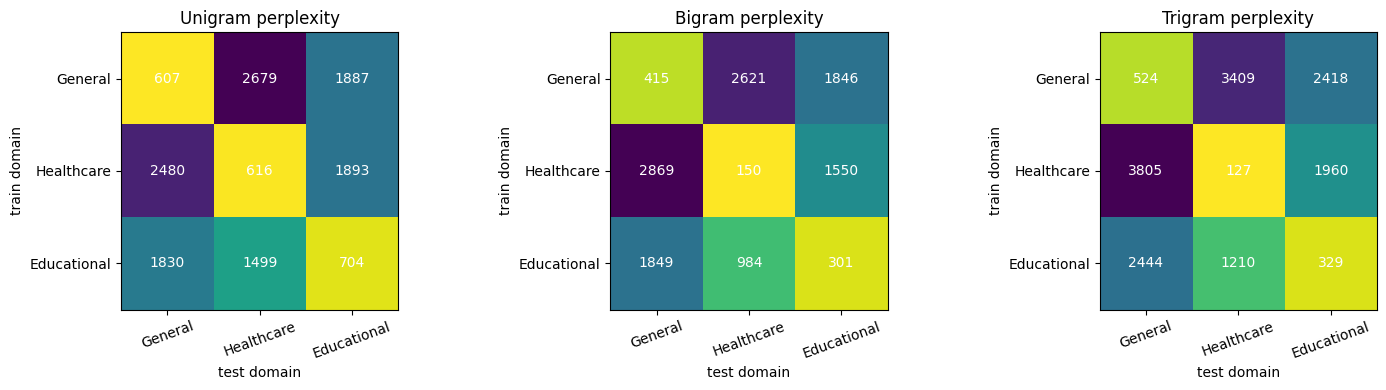

=== Conclusion ===
Unigram: in-domain model has the lowest perplexity on 3/3 test sets
Bigram: in-domain model has the lowest perplexity on 3/3 test sets
Trigram: in-domain model has the lowest perplexity on 3/3 test sets
Next-word on General: best top-1 model = General, best top-3 model = General
Next-word on Healthcare: best top-1 model = Healthcare, best top-3 model = Healthcare
Next-word on Educational: best top-1 model = Educational, best top-3 model = Educational
Healthcare test: trigram perplexity 127 (in-domain) vs 3409 (general model) -> 96.3% lower
Educational test: trigram perplexity 329 (in-domain) vs 2418 (general model) -> 86.4% lower


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, n in enumerate((1, 2, 3)):
    im = ax[i].imshow(ppl[n].values, cmap="viridis_r")
    ax[i].set_xticks(range(3)); ax[i].set_xticklabels(DOMS, rotation=20)
    ax[i].set_yticks(range(3)); ax[i].set_yticklabels(DOMS)
    ax[i].set_xlabel("test domain"); ax[i].set_ylabel("train domain")
    ax[i].set_title(["", "Unigram", "Bigram", "Trigram"][n] + " perplexity")
    for r in range(3):
        for c in range(3): ax[i].text(c, r, f"{ppl[n].values[r, c]:.0f}", ha="center", va="center", color="w")
plt.tight_layout(); plt.savefig("perplexity_heatmaps.png", dpi=200); plt.show()

print("=== Conclusion ===")
for n in (1, 2, 3):
    wins = sum(ppl[n][te].idxmin() == te for te in DOMS)
    print(f"{['','Unigram','Bigram','Trigram'][n]}: in-domain model has the lowest perplexity on {wins}/3 test sets")
for te in DOMS:
    best1 = top1[te].idxmax(); best3 = top3[te].idxmax()
    print(f"Next-word on {te}: best top-1 model = {best1}, best top-3 model = {best3}")
for te in DOMS:
    own = ppl[3].loc[te, te]; gen = ppl[3].loc["General", te]
    if te != "General":
        print(f"{te} test: trigram perplexity {own:.0f} (in-domain) vs {gen:.0f} (general model) -> {100*(gen-own)/gen:.1f}% lower")

## 9. Interactive demo: type a sentence, get its probability
Type any sentence. The program shows how likely each domain model finds it (probability, log-probability, perplexity), which domain it most resembles, and what each model would predict as the next word. Type `quit` (or press Enter on an empty line) to stop.

In [ ]:
def analyse(text, show_next=True):
    toks = tokenize(text)
    if not toks:
        print("Please type some words."); return
    mapped = [w if w in VOCAB else "<UNK>" for w in toks]
    unknown = [w for w, m in zip(toks, mapped) if m == "<UNK>"]
    rows = []
    for d in DOMS:
        m = models[3][d]
        lp = m.sentence_logprob(mapped)                  # log2 P(sentence)
        rows.append({"Model": d,
                     "Probability": f"{2**lp:.3e}",
                     "log2 P": round(lp, 2),
                     "Avg log2 P / word": round(lp / (len(mapped) + 1), 2),
                     "Perplexity": round(2 ** (-lp / (len(mapped) + 1)), 1)})
    df = pd.DataFrame(rows).set_index("Model")
    print(f'\nSentence: "{text}"')
    print(f"Words: {len(toks)} | words not in vocabulary (treated as <UNK>): {unknown if unknown else 'none'}")
    display(df)
    best = max(DOMS, key=lambda d: models[3][d].sentence_logprob(mapped))
    print(f"--> Most likely domain: {best} (highest probability; lower perplexity = better fit)")
    if show_next:
        ctx = ([BOS, BOS] + mapped)[-2:]
        print(f"Next-word predictions after '{' '.join(toks[-2:])}':")
        for d in DOMS:
            print(f"   {d:12s}: {', '.join(models[3][d].predict(ctx[0], ctx[1], 3))}")

# a few ready-made examples
for ex in ["patients with high blood pressure should take the medication every day",
           "students learn that plants use sunlight to make energy",
           "the president said that the government would meet again on monday"]:
    analyse(ex)


Sentence: "patients with high blood pressure should take the medication every day"
Words: 11 | words not in vocabulary (treated as <UNK>): none


,Probability,log2 P,Avg log2 P / word,Perplexity
Model,,,,
General,2.223e-35,-115.12,-9.59,772.2
Healthcare,1.866e-23,-75.50,-6.29,78.4
Educational,2.524e-35,-114.93,-9.58,764.1


--> Most likely domain: Healthcare (highest probability; lower perplexity = better fit)
Next-word predictions after 'every day':
   General     : and, it, from
   Healthcare  : the, or, before
   Educational : the, from, without

Sentence: "students learn that plants use sunlight to make energy"
Words: 9 | words not in vocabulary (treated as <UNK>): none


,Probability,log2 P,Avg log2 P / word,Perplexity
Model,,,,
General,2.982e-35,-114.69,-11.47,2835.0
Healthcare,5.800e-37,-120.38,-12.04,4204.0
Educational,1.094e-24,-79.60,-7.96,248.9


--> Most likely domain: Educational (highest probability; lower perplexity = better fit)
Next-word predictions after 'make energy':
   General     : and, commission, the
   Healthcare  : production, producing, particularly
   Educational : is, of, to

Sentence: "the president said that the government would meet again on monday"
Words: 11 | words not in vocabulary (treated as <UNK>): none


,Probability,log2 P,Avg log2 P / word,Perplexity
Model,,,,
General,3.635e-28,-91.15,-7.60,193.5
Healthcare,2.328e-50,-164.88,-13.74,13679.9
Educational,8.017e-50,-163.09,-13.59,12340.5


--> Most likely domain: General (highest probability; lower perplexity = better fit)
Next-word predictions after 'on monday':
   General     : the, night, in
   Healthcare  : the, of, and
   Educational : the, of, a


In [ ]:
# Interactive loop: type your own sentences (type quit to stop)
while True:
    text = input("\nEnter a sentence (or 'quit'): ")
    if text.strip().lower() in ("quit", "exit", ""):
        print("Done."); break
    analyse(text)


Enter a sentence (or 'quit'): The patient was given antibiotics for the infection.

Sentence: "The patient was given antibiotics for the infection."
Words: 8 | words not in vocabulary (treated as <UNK>): none


,Probability,log2 P,Avg log2 P / word,Perplexity
Model,,,,
General,1.574e-31,-102.33,-11.37,2645.9
Healthcare,5.684e-18,-57.29,-6.37,82.4
Educational,4.014e-26,-84.37,-9.37,663.5


--> Most likely domain: Healthcare (highest probability; lower perplexity = better fit)
Next-word predictions after 'the infection':
   General     : the, of, and
   Healthcare  : is, spreads, and
   Educational : from, by, of
